# Auditoría de fugas e inflación

Un primer resultado con ROC-AUC de 0.95 parecía excelente. Este notebook explica por qué no lo era: de dónde sale cada punto que se pierde hasta llegar a la cifra oficial.

**No calcula nada sobre 2017.** Lee `outputs/audit/inflation.csv`, escrito por `hotel-ml audit`, los resultados guardados del test y el diagnóstico de `outputs/experiments/`, que usa solo llegadas anteriores a 2017.

In [1]:
%matplotlib inline

import json

import matplotlib as mpl
import pandas as pd
from IPython.display import Markdown, display
from matplotlib.figure import Figure

from hotel_cancellation import config
from hotel_cancellation.data import schema
from hotel_cancellation.evaluation import plots

settings = config.get_settings()
mpl.rcParams.update(plots.STYLE)
pd.options.display.float_format = "{:.4f}".format

inflation = pd.read_csv(settings.audit_dir / "inflation.csv")
steps = inflation.set_index("step")
metrics = pd.read_csv(settings.final_evaluation_dir / "metrics.csv")
scenario = pd.read_csv(settings.final_evaluation_dir / "scenario_special_requests.csv")
bootstrap = pd.read_csv(settings.final_evaluation_dir / "bootstrap.csv")
cohorts = pd.read_csv(settings.experiments_dir / "feature_availability_cohorts.csv")
bins = pd.read_csv(settings.experiments_dir / "feature_availability_bins.csv")
summary = json.loads(
    (settings.experiments_dir / "feature_availability_summary.json").read_text(encoding="utf-8")
)


def note(text):
    display(Markdown(text))


def percent(share):
    return f"{100 * share:.1f} %"


def count(number):
    return f"{number:,}".replace(",", " ")

## 1. Los cuatro escalones

Cada escalón quita un motivo de inflación. Los tres primeros son el mismo XGBoost, con árboles muy profundos; el cuarto copia la cifra publicada del modelo oficial, que no se mide dos veces.

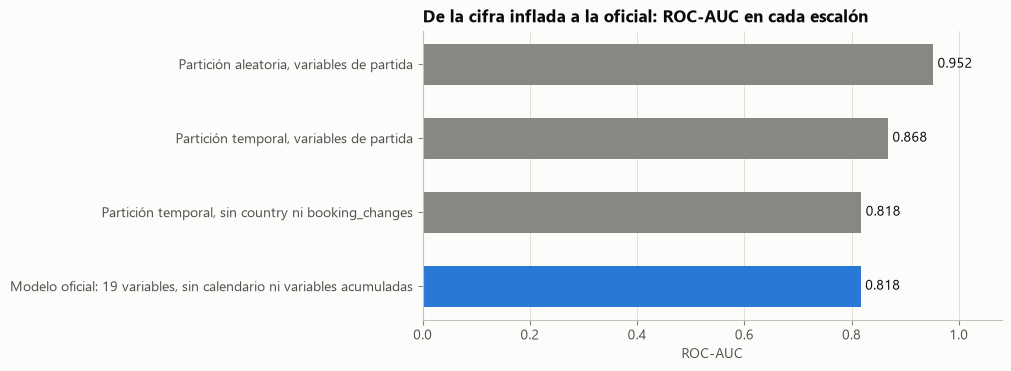

,label,train_rows,test_rows,test_rows_already_in_train,roc_auc,pr_auc
0,"Partición aleatoria, variables de partida",94850,23713,0.3195,0.9524,0.9339
1,"Partición temporal, variables de partida",78054,40509,0.0000,0.8683,0.8270
2,"Partición temporal, sin country ni booking_cha...",78054,40509,0.0000,0.8184,0.7802
3,"Modelo oficial: 19 variables, sin calendario n...",78054,40509,NaN,0.8175,0.7608


In [2]:
display(plots.inflation_figure(inflation))
inflation[["label", "train_rows", "test_rows", "test_rows_already_in_train", "roc_auc", "pr_auc"]]

## 2. Primer escalón: evaluar en el futuro

Una partición aleatoria mezcla reservas de todas las fechas, y por eso el modelo ve el futuro al entrenar. Además, muchas filas de test están repetidas en train.

In [3]:
first = steps.loc["random_split_starting_variables"]
second = steps.loc["temporal_split_starting_variables"]
note(
    f"El ROC-AUC baja de **{first['roc_auc']:.4f}** a **{second['roc_auc']:.4f}** sin cambiar "
    f"modelo ni variables. En la partición aleatoria, el "
    f"{percent(first['test_rows_already_in_train'])} de las filas de test ya estaba en train; en "
    f"la temporal, el {percent(second['test_rows_already_in_train'])}."
)

El ROC-AUC baja de **0.9524** a **0.8683** sin cambiar modelo ni variables. En la partición aleatoria, el 32.0 % de las filas de test ya estaba en train; en la temporal, el 0.0 %.

**Decisión.** La evaluación oficial corta por fecha de llegada ([ADR 0001](../docs/adr/0001-evaluacion-temporal.md)).

## 3. Segundo escalón: variables que no se conocen al confirmar

Antonio, de Almeida y Nunes (2019), en *Data Science Journal* ([doi 10.5334/dsj-2019-032](https://doi.org/10.5334/dsj-2019-032)), documentan la fuga de `country`: el país se corrige en el check-in, y las reservas canceladas conservan el valor inicial. `booking_changes` cuenta cambios a lo largo de la vida de la reserva.

In [4]:
third = steps.loc["temporal_split_without_documented_leaks"]
official = steps.loc["official_model"]
note(
    f"Sin esas dos variables, el ROC-AUC baja de **{second['roc_auc']:.4f}** a "
    f"**{third['roc_auc']:.4f}**.\n\n"
    f"El tercer escalón y el modelo oficial ({official['roc_auc']:.4f}) casi coinciden, y **es "
    "casualidad**: el tercero conserva `total_of_special_requests`, el calendario y árboles de "
    "profundidad 16, y esos efectos se compensan. No significa que esas decisiones no importen."
)

Sin esas dos variables, el ROC-AUC baja de **0.8683** a **0.8184**.

El tercer escalón y el modelo oficial (0.8175) casi coinciden, y **es casualidad**: el tercero conserva `total_of_special_requests`, el calendario y árboles de profundidad 16, y esos efectos se compensan. No significa que esas decisiones no importen.

## 4. El diagnóstico de acumulación

No todas las fugas están documentadas. Para las demás se usa un diagnóstico propio: una reserva cancelada deja de cambiar al cancelarse, de modo que **una variable que se acumula debe crecer con la parte de vida transcurrida**. Se mide con correlación de Spearman, y `booking_changes` hace de control positivo. Solo se usan llegadas anteriores a 2017.

In [5]:
note(
    f"Reservas canceladas analizadas: **{count(summary['rows_used'])}**, de ellas "
    f"**{count(summary['control_rows'])}** de {summary['control_segment']}. Variables que el "
    f"diagnóstico señala en {summary['control_segment']}: **{', '.join(summary['flagged'])}**."
)
compared = cohorts[cohorts["variable"].isin(["total_of_special_requests", "booking_changes"])]
compared.pivot(index="cohort", columns="variable", values="rho")[
    ["total_of_special_requests", "booking_changes"]
]

Reservas canceladas analizadas: **27 389**, de ellas **11 002** de Online TA. Variables que el diagnóstico señala en Online TA: **total_of_special_requests**.

variable,total_of_special_requests,booking_changes
cohort,,
all,0.0658,0.0903
city,0.1000,0.0932
no_deposit_unique_rows,0.1618,0.1150
online_ta,0.2443,0.1046
online_ta_city,0.2896,0.1104
online_ta_resort,0.1638,0.0996
resort,0.0039,0.0951
unique_rows,0.1485,0.1168


La tabla da la ρ de cada cohorte. **El efecto no es uniforme**: `total_of_special_requests` supera al control en seis de las ocho cohortes, con claridad en Online TA, y no lo alcanza ni en el total ni en Resort Hotel. Por eso excluirla es una decisión de cautela, no una demostración.

Las tandas de `Non Refund`, en su mayoría duplicados exactos que se cancelan juntos, distorsionan la medida global, y por eso el control se hace en Online TA.

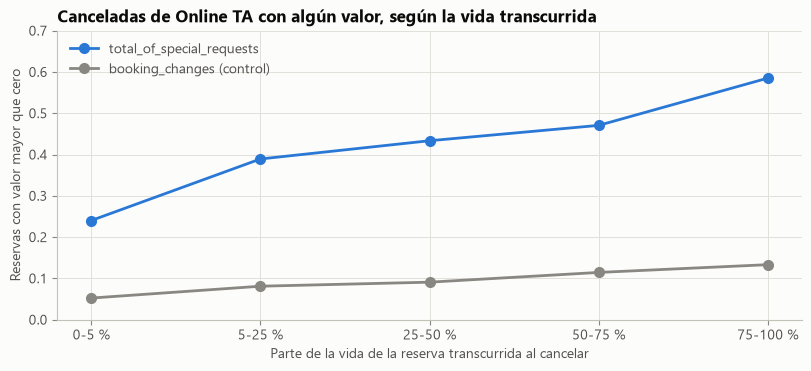

In [6]:
control = bins[bins["scope"] == "control"]
nonzero = control.pivot(index="life_bin", columns="variable", values="nonzero_share").loc[
    lambda table: sorted(table.index, key=lambda name: int(name.split("_")[0]))
]

figure = Figure(figsize=(8, 3.6), layout="constrained")
axis = figure.subplots()
labels = [name.replace("_", "-") + " %" for name in nonzero.index]
axis.plot(
    labels,
    nonzero["total_of_special_requests"],
    "-o",
    color=plots.ACCENT,
    markersize=7,
    label="total_of_special_requests",
)
axis.plot(
    labels,
    nonzero["booking_changes"],
    "-o",
    color=plots.MUTED,
    markersize=7,
    label="booking_changes (control)",
)
axis.set_title("Canceladas de Online TA con algún valor, según la vida transcurrida")
axis.set_xlabel("Parte de la vida de la reserva transcurrida al cancelar")
axis.set_ylabel("Reservas con valor mayor que cero")
axis.set_ylim(0, 0.7)
axis.legend(loc="upper left")
display(figure)

## 5. Qué cuesta excluirla: el escenario informativo

El protocolo fijó, antes del test, medir también un Random Forest igual al campeón con `total_of_special_requests` añadida. Es **solo informativo y no puede cambiar el campeón**. Sirve para decir cuánto se renuncia por cautela.

In [7]:
official_all = metrics[
    (metrics["model"] == "random_forest")
    & (metrics["threshold_name"] == "decision")
    & (metrics["subset"] == "all")
].iloc[0]
scenario_all = scenario[(scenario["threshold_name"] == "decision") & (scenario["subset"] == "all")]
scenario_all = scenario_all.iloc[0]
interval = bootstrap[
    (bootstrap["model"] == "special_requests_scenario") & (bootstrap["blocks"] == "hotel_date")
].iloc[0]
note(
    f"ROC-AUC de **{official_all['roc_auc']:.4f}** sin la variable y de "
    f"**{scenario_all['roc_auc']:.4f}** con ella. La diferencia pareada va de "
    f"[{interval['gap_ci_low']:+.4f}, {interval['gap_ci_high']:+.4f}], con bloques de hotel y "
    "fecha."
)
scenario[scenario["threshold_name"] == "decision"][
    ["subset", "rows", "roc_auc", "pr_auc", "brier", "calibration_slope", "recall", "f1"]
]

ROC-AUC de **0.8175** sin la variable y de **0.8369** con ella. La diferencia pareada va de [+0.0155, +0.0233], con bloques de hotel y fecha.

,subset,rows,roc_auc,pr_auc,brier,calibration_slope,recall,f1
0,all,40509,0.8369,0.7835,0.1577,0.7758,0.8975,0.6775
1,unique,29667,0.7782,0.6122,0.1785,0.7238,0.8705,0.6037
2,no_deposit,36356,0.7792,0.5856,0.1754,0.7568,0.8609,0.5977
3,non_refund,4126,0.9997,1.0000,0.0011,3.7636,1.0000,0.9990


Si la variable no fuera una fuga, el modelo oficial estaría dejando esa mejora sobre la mesa, y por eso se publica. Si lo es, esa mejora no existiría al confirmar la reserva. Con este archivo, que guarda solo el valor final, **no se puede saber con certeza**. Se elige la opción más prudente y se declara.

## 6. Lo que este diagnóstico no puede ver

- **Detecta acumulación, no sobrescritura.** Una variable que se reemplaza sin crecer, como una tarifa, no deja esta huella. `adr` queda como limitación.
- **Solo mide las canceladas.** Las reservas que llegan al hotel no tienen un momento de congelación comparable.
- **Es observacional.** Quien cancela enseguida puede ser un cliente distinto. Comparar dentro de grupos de hotel, mes y antelación reduce ese riesgo, pero no lo elimina.
- **2017 no es virgen.** La auditoría había visto esos datos antes del test: lo declara el [protocolo](../docs/protocolo.md), y de ella salen `ADR_UPPER_LIMIT`, `min_frequency=50` y las rejillas de búsqueda.

La evidencia variable por variable está en la [data card](../docs/data_card.md).

In [8]:
pd.Series(schema.FORBIDDEN_FEATURES, name="motivo (en schema.py)").to_frame()

,motivo (en schema.py)
reservation_status,Final outcome of the booking: it restates the ...
reservation_status_date,Date of the final status: only known after the...
country,Documented leakage (Antonio et al. 2019): it i...
required_car_parking_spaces,Only known at check-in or later.
assigned_room_type,Only known at check-in or later.
booking_changes,Accumulates over the life of the booking.
total_of_special_requests,Accumulates over the life of the booking.
arrival_date_year,Calendar variable: it does not generalize and ...
arrival_date_month,Calendar variable: it does not generalize and ...
arrival_date_week_number,Calendar variable: it does not generalize and ...
